# Customer Segmentation — K-Means Clustering on RFM Features

**Data:** Online Retail II (UCI), UK online gift retailer, Dec 2009 – Dec 2011
**Input:** `retail.customer_rfm`, built in PostgreSQL by `sql/05_rfm.sql`
**Goal:** group customers by behaviour (Recency, Frequency, Monetary), then compare the clusters with the rule-based RFM segments.

Pipeline: **PostgreSQL → pandas → log transform → scale → K-means → profile → write back to PostgreSQL**

## 1. Setup and connect to PostgreSQL
Change `PASSWORD` to the password you set when installing PostgreSQL.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

USER, PASSWORD, HOST, PORT, DB = "postgres", "cmm.4Dit", "localhost", 5432, "customer_segmentation"
DB_URL = os.getenv("DB_URL", f"postgresql+psycopg2://{USER}:{PASSWORD}@{HOST}:{PORT}/{DB}")
engine = create_engine(DB_URL)

os.makedirs("../images", exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

## 2. Load the RFM features with SQL

In [2]:
query = """
    SELECT customer_id, country, recency_days, frequency, monetary,
           avg_order_value, distinct_products, return_rate, rfm_segment
    FROM retail.customer_rfm
"""
df = pd.read_sql(query, engine)
print(f"{len(df):,} customers")   # expect 5,832
df.describe().T

5,832 customers


,count,mean,std,min,25%,50%,75%,max
customer_id,"5,832.00","15,322.09","1,713.72","12,346.00","13,842.75","15,323.50","16,802.25","18,287.00"
recency_days,"5,832.00",200.38,208.38,1.00,26.00,96.00,379.00,739.00
frequency,"5,832.00",6.27,12.77,1.00,1.00,3.00,7.00,373.00
monetary,"5,832.00","2,805.48","13,847.92",2.90,333.79,843.74,"2,179.89","578,408.64"
avg_order_value,"5,832.00",384.70,"1,256.64",2.95,176.60,278.17,410.60,"84,236.25"
distinct_products,"5,832.00",82.42,116.62,1.00,19.00,45.00,104.00,"2,546.00"
return_rate,"5,832.00",0.02,0.06,0.00,0.00,0.00,0.01,1.00


## 3. Why transform? The features are heavily skewed
K-means uses distances, so a few customers with huge spend would dominate. `log1p` pulls in the long tail, then `StandardScaler` puts all three features on the same scale (mean 0, std 1).

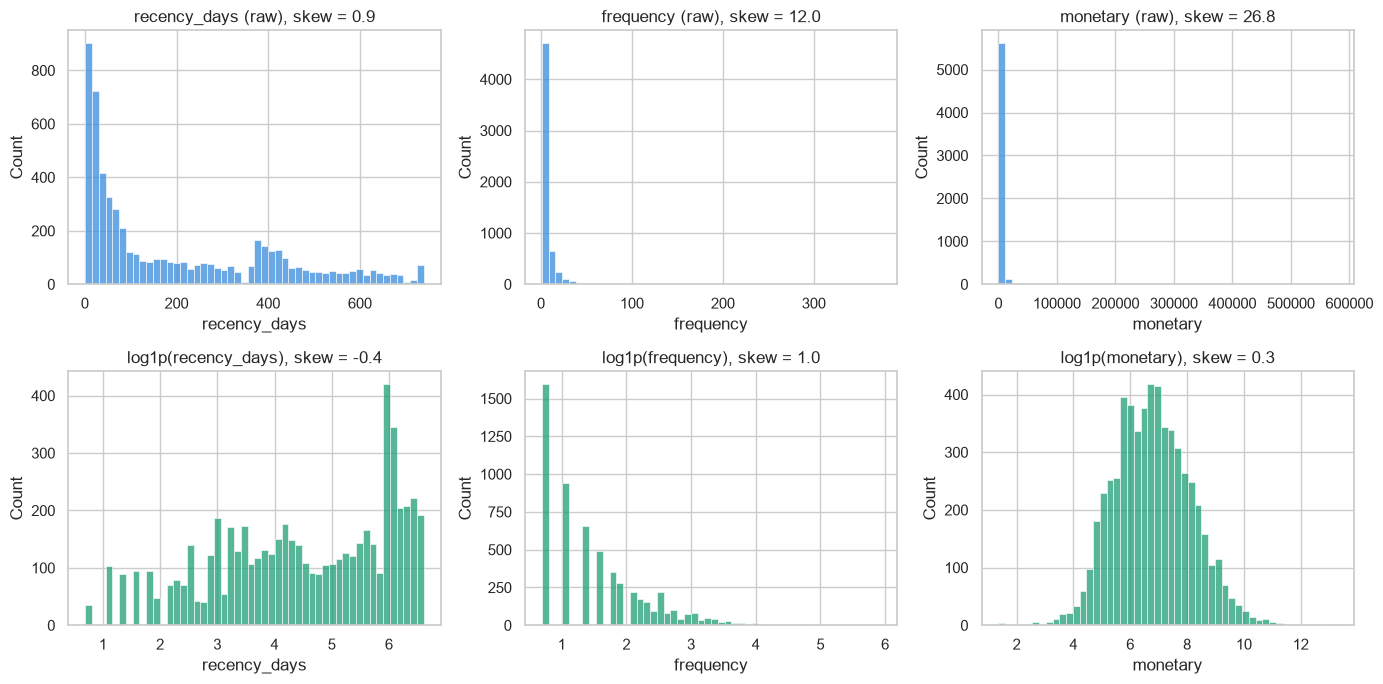

In [3]:
features = ["recency_days", "frequency", "monetary"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, col in enumerate(features):
    sns.histplot(df[col], bins=50, ax=axes[0, i], color="#378ADD")
    axes[0, i].set_title(f"{col} (raw), skew = {df[col].skew():.1f}")
    sns.histplot(np.log1p(df[col]), bins=50, ax=axes[1, i], color="#1D9E75")
    axes[1, i].set_title(f"log1p({col}), skew = {np.log1p(df[col]).skew():.1f}")
plt.tight_layout()
plt.savefig("../images/01_skew.png", dpi=120)
plt.show()

In [4]:
X_log = np.log1p(df[features])
scaler = StandardScaler()
X = scaler.fit_transform(X_log)
pd.DataFrame(X, columns=features).describe().round(2)

,recency_days,frequency,monetary
count,"5,832.00","5,832.00","5,832.00"
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-2.47,-1.06,-3.95
25%,-0.76,-1.06,-0.71
50%,0.07,-0.20,-0.04
75%,0.96,0.66,0.65
max,1.40,5.42,4.71


## 4. Choose the number of clusters
Two checks: the **elbow** (where adding clusters stops reducing inertia much) and the **silhouette score** (how well separated the clusters are, −1 to 1, higher is better).

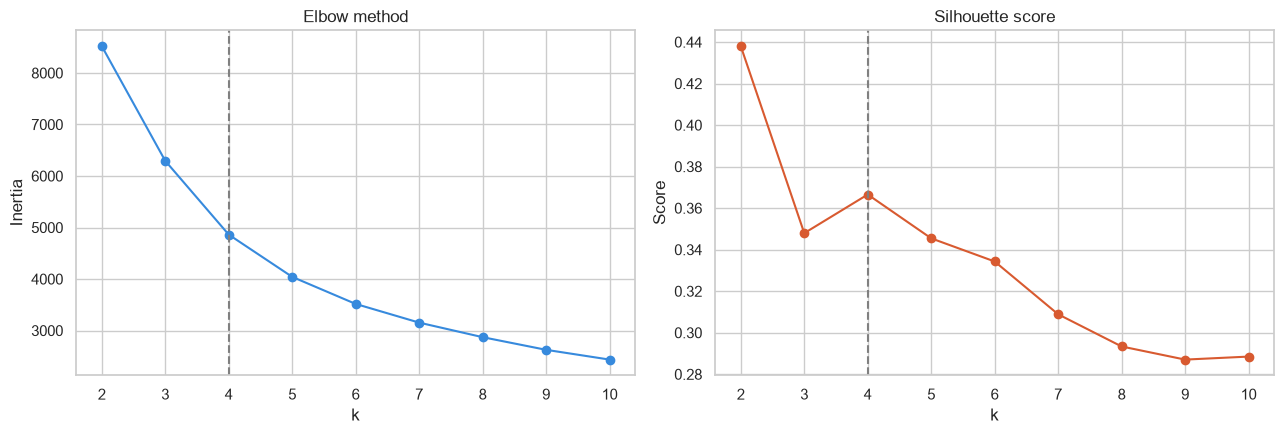

,k,inertia,silhouette
0,2,"8,520.90",0.44
1,3,"6,293.76",0.35
2,4,"4,861.87",0.37
3,5,"4,041.51",0.34
4,6,"3,516.26",0.33
5,7,"3,153.45",0.31
6,8,"2,871.03",0.29
7,9,"2,625.40",0.29
8,10,"2,435.73",0.29


In [5]:
ks = range(2, 11)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(ks, inertia, "o-", color="#378ADD"); ax1.set_title("Elbow method"); ax1.set_xlabel("k"); ax1.set_ylabel("Inertia")
ax2.plot(ks, silhouette, "o-", color="#D85A30"); ax2.set_title("Silhouette score"); ax2.set_xlabel("k"); ax2.set_ylabel("Score")
for ax in (ax1, ax2): ax.axvline(4, ls="--", color="grey")
plt.tight_layout()
plt.savefig("../images/02_choose_k.png", dpi=120)
plt.show()

pd.DataFrame({"k": list(ks), "inertia": inertia, "silhouette": silhouette}).round(3)

**Decision: k = 4.** The silhouette score is highest at k = 2, but two groups ("good" vs "bad" customers) are too coarse to act on. After k = 2, the silhouette peaks again at k = 4, which is also where the elbow bends. Four clusters also give four distinct marketing actions.

## 5. Fit K-means with k = 4 and name the clusters

In [6]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
df["cluster_id"] = km.labels_

profile = df.groupby("cluster_id").agg(
    customers=("customer_id", "count"),
    recency_median=("recency_days", "median"),
    frequency_median=("frequency", "median"),
    monetary_median=("monetary", "median"),
    revenue=("monetary", "sum"),
)

# Name clusters with rules on their medians, so names stay correct even if
# K-means numbers the clusters differently on another computer.
vip  = profile["monetary_median"].idxmax()
lost = profile["recency_median"].idxmax()
rest = profile.drop([vip, lost])
developing = rest["recency_median"].idxmin()
at_risk    = rest["recency_median"].idxmax()
names = {vip: "VIP", developing: "Recent Developing", at_risk: "At-Risk Regulars", lost: "Lost One-Timers"}
df["cluster"] = df["cluster_id"].map(names)

order = ["VIP", "Recent Developing", "At-Risk Regulars", "Lost One-Timers"]
summary = (df.groupby("cluster")
             .agg(customers=("customer_id", "count"),
                  recency_median=("recency_days", "median"),
                  frequency_median=("frequency", "median"),
                  monetary_median=("monetary", "median"),
                  aov_median=("avg_order_value", "median"),
                  revenue=("monetary", "sum"))
             .reindex(order))
summary["pct_customers"] = 100 * summary["customers"] / summary["customers"].sum()
summary["pct_revenue"]   = 100 * summary["revenue"] / summary["revenue"].sum()
summary.drop(columns="revenue").round(1)

,customers,recency_median,frequency_median,monetary_median,aov_median,pct_customers,pct_revenue
cluster,,,,,,,
VIP,1190,17.00,13.00,"4,807.80",366.80,20.40,73.70
Recent Developing,1250,24.00,3.00,703.40,252.10,21.40,6.20
At-Risk Regulars,1438,183.00,5.00,"1,435.40",320.90,24.70,16.40
Lost One-Timers,1954,402.00,1.00,266.90,202.30,33.50,3.70


## 6. Profile the clusters

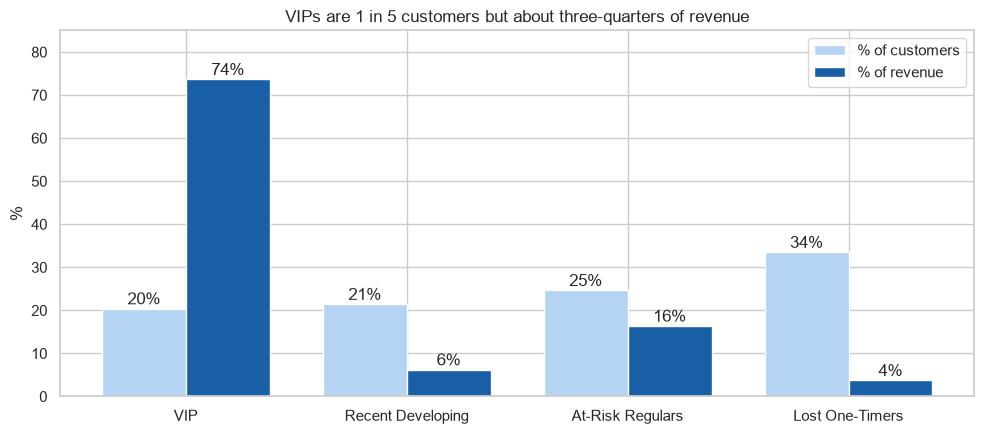

In [7]:
palette = {"VIP": "#185FA5", "Recent Developing": "#1D9E75", "At-Risk Regulars": "#EF9F27", "Lost One-Timers": "#B4B2A9"}

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(order)); w = 0.38
ax.bar(x - w/2, summary["pct_customers"], w, label="% of customers", color="#B5D4F4")
ax.bar(x + w/2, summary["pct_revenue"], w, label="% of revenue", color="#185FA5")
for i, (c, r) in enumerate(zip(summary["pct_customers"], summary["pct_revenue"])):
    ax.text(i - w/2, c + 1, f"{c:.0f}%", ha="center"); ax.text(i + w/2, r + 1, f"{r:.0f}%", ha="center")
ax.set_xticks(x, order); ax.set_ylabel("%"); ax.set_ylim(0, 85); ax.set_title("VIPs are 1 in 5 customers but about three-quarters of revenue"); ax.legend()
plt.tight_layout(); plt.savefig("../images/03_customers_vs_revenue.png", dpi=120); plt.show()

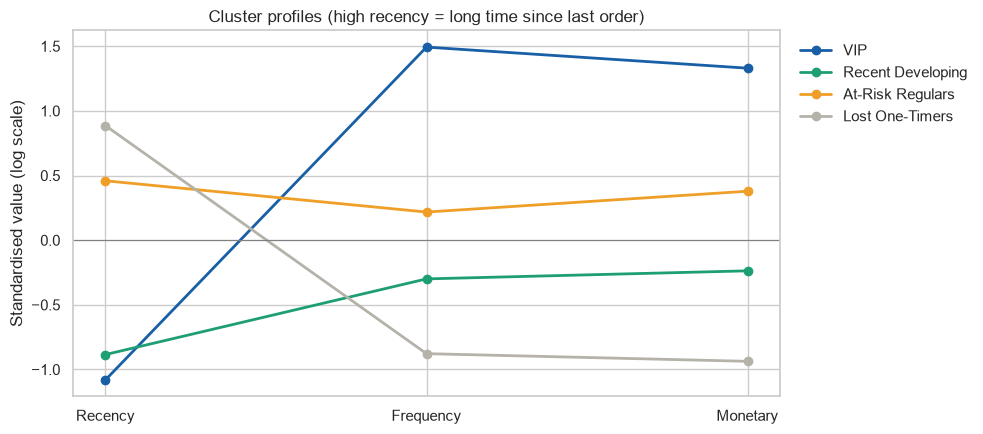

In [8]:
# "Snake plot": average standardised value of each feature per cluster
scaled = pd.DataFrame(X, columns=["Recency", "Frequency", "Monetary"])
scaled["cluster"] = df["cluster"]
snake = scaled.groupby("cluster").mean().reindex(order)

fig, ax = plt.subplots(figsize=(10, 4.5))
for c in order:
    ax.plot(snake.columns, snake.loc[c], "o-", label=c, color=palette[c], lw=2)
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("Standardised value (log scale)"); ax.set_title("Cluster profiles (high recency = long time since last order)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False); plt.tight_layout(); plt.savefig("../images/04_snake_plot.png", dpi=120); plt.show()

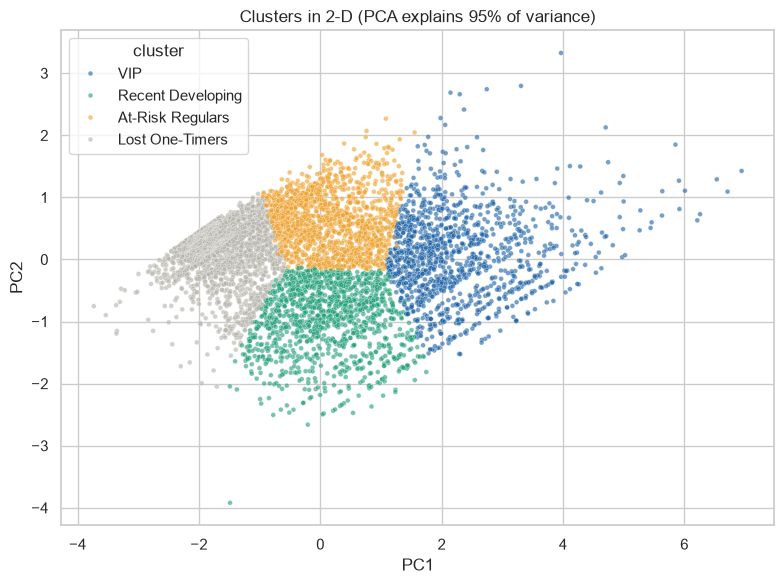

In [9]:
# 2-D view of the clusters with PCA (for visualisation only)
pca = PCA(n_components=2, random_state=42)
pts = pca.fit_transform(X)
plot_df = pd.DataFrame(pts, columns=["PC1", "PC2"]); plot_df["cluster"] = df["cluster"]

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="cluster", hue_order=order, palette=palette, s=12, alpha=0.6, ax=ax)
ax.set_title(f"Clusters in 2-D (PCA explains {pca.explained_variance_ratio_.sum():.0%} of variance)")
plt.tight_layout(); plt.savefig("../images/05_pca_clusters.png", dpi=120); plt.show()

## 7. Clusters vs rule-based RFM segments
Do the data-driven clusters agree with the RFM business rules from SQL? Each row shows how one RFM segment is split across the clusters.

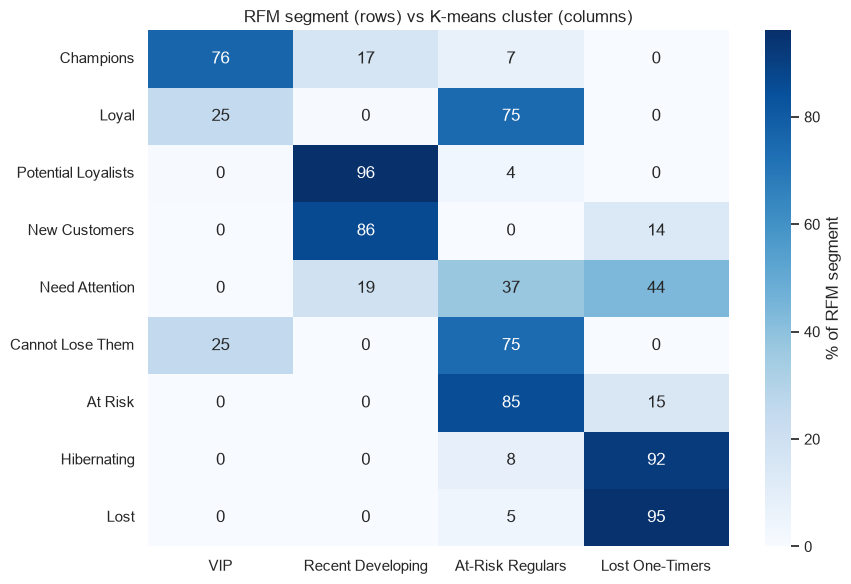

In [10]:
ct = pd.crosstab(df["rfm_segment"], df["cluster"], normalize="index").reindex(columns=order) * 100
seg_order = ["Champions", "Loyal", "Potential Loyalists", "New Customers", "Need Attention",
             "Cannot Lose Them", "At Risk", "Hibernating", "Lost"]
ct = ct.reindex(seg_order)

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of RFM segment"}, ax=ax)
ax.set_title("RFM segment (rows) vs K-means cluster (columns)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("../images/06_rfm_vs_clusters.png", dpi=120); plt.show()

## 8. Save the clusters back to PostgreSQL
So the results can be queried, joined and reported with SQL (`sql/06_cluster_analysis.sql`).

In [11]:
df[["customer_id", "cluster"]].to_sql("customer_clusters", engine, schema="retail", if_exists="replace", index=False)
pd.read_sql("SELECT cluster, COUNT(*) AS customers FROM retail.customer_clusters GROUP BY cluster ORDER BY customers DESC", engine)

,cluster,customers
0,Lost One-Timers,1954
1,At-Risk Regulars,1438
2,Recent Developing,1250
3,VIP,1190


## 9. Recommended actions per cluster

| Cluster | Who they are | Action |
|---|---|---|
| **VIP** | Bought recently, often, and spend the most | Protect: account manager, early access, volume discounts. Never discount-bomb them. |
| **Recent Developing** | Recent but only a few orders | Grow: second-order incentives, product recommendations based on first basket |
| **At-Risk Regulars** | Used to buy regularly, quiet for ~6 months | Win back now: personalised re-engagement before they become Lost |
| **Lost One-Timers** | One order, over a year ago | Low-cost only: seasonal campaign before Q4, otherwise don't spend on them |